# MLP for Tabular Health Prediction

## 1. Project Overview

This project develops a Multi-Layer Perceptron (MLP) for binary classification using the CDC Diabetes Health Indicators dataset.

The model will be implemented and trained using PyTorch in Google Colab. Its performance will be evaluated and compared with a Random Forest baseline. A Streamlit application will then be developed to demonstrate inference using the saved model and preprocessing artifacts.

## 2. Objectives

- Acquire and inspect the healthcare dataset.
- Perform exploratory data analysis and data-quality checks.
- Develop a preprocessing pipeline for numerical and categorical features.
- Train an MLP using PyTorch.
- Monitor training and validation loss using learning curves.
- Evaluate performance using a confusion matrix, precision, recall, and F1-score.
- Compare the MLP with a Random Forest baseline.
- Save the trained model weights and preprocessing artifacts.
- Integrate the trained model into a Streamlit application.

## 3. Dataset

**Name:** CDC Diabetes Health Indicators  
**Source:** UCI Machine Learning Repository  
**Dataset ID:** 891  
**Task:** Binary classification  
**Target:** `Diabetes_binary`

Target interpretation:
- `0`: No diabetes
- `1`: Prediabetes or diabetes

Dataset reference: https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators

## 4. Experimental Methodology

The dataset will be inspected before preprocessing. Training, validation, and test sets will be separated to prevent data leakage. Preprocessing parameters will be fitted using training data only.

The MLP and Random Forest will use consistent data splits and evaluation metrics. Final test-set evaluation will be performed only after model selection.

## 5. Deliverables

1. Documented Jupyter Notebook
2. Trained PyTorch model weights
3. Saved preprocessing artifacts
4. Learning curves and evaluation plots
5. MLP versus Random Forest comparison
6. Streamlit inference application

## 6. Limitations

This project is intended for machine-learning education and demonstration. Predictions are not medical diagnoses. Model performance and generalization must be evaluated before drawing conclusions.


## Environment setup

In [1]:
# ============================================================
# Step 1: Environment Setup
# Project: MLP for Tabular Health Prediction
# Purpose: Import core libraries and verify the runtime.
# ============================================================

import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("PyTorch version:", torch.__version__)
print("Compute device:", DEVICE)

Python version: 3.13.16
NumPy version: 2.1.3
Pandas version: 2.2.3
PyTorch version: 2.11.0+cpu
Compute device: cpu


## Install dataset client

In [2]:
# ============================================================
# Step 2A: Install UCI dataset client
# Purpose: Access the dataset through the UCI repository API.
# ============================================================

%pip install -q ucimlrepo

## Fetch dataset and validate schema

In [3]:
# ============================================================
# Step 2B: Dataset Acquisition
# Source: UCI Machine Learning Repository, Dataset ID 891
# Purpose: Load features, targets, and dataset metadata.
# ============================================================

from ucimlrepo import fetch_ucirepo

cdc_diabetes_health_indicators = fetch_ucirepo(id=891)

# Create independent DataFrame copies for our experiment.
X = cdc_diabetes_health_indicators.data.features.copy()
y = cdc_diabetes_health_indicators.data.targets.copy()

print("Dataset:", cdc_diabetes_health_indicators.metadata.name)
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget columns:")
print(y.columns.tolist())

print("\nFeature preview:")
display(X.head())

print("\nTarget preview:")
display(y.head())

Dataset: CDC Diabetes Health Indicators
Features shape: (253680, 21)
Target shape: (253680, 1)

Feature columns:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target columns:
['Diabetes_binary']

Feature preview:


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,1,1,40,1,0,0,0,0,1,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,25,1,0,0,1,0,0,...,0,1,3,0,0,0,0,7,6,1
2,1,1,1,28,0,0,0,0,1,0,...,1,1,5,30,30,1,0,9,4,8
3,1,0,1,27,0,0,0,1,1,1,...,1,0,2,0,0,0,0,11,3,6
4,1,1,1,24,0,0,0,1,1,1,...,1,0,2,3,0,0,0,11,5,4



Target preview:


,Diabetes_binary
0,0
1,0
2,0
3,0
4,0


## Basic data integrity checks

In [4]:
# ============================================================
# Step 2C: Initial Data Integrity Audit
# Purpose: Verify dataset dimensions, schema, and target labels.
# ============================================================

assert len(X) == len(y), "Feature and target row counts differ."
assert X.index.equals(y.index), "Feature and target indices differ."

print("Feature data types:")
display(X.dtypes.value_counts().rename("Column count").to_frame())

print("\nMissing values:")
print("X:", X.isna().sum().sum())
print("y:", y.isna().sum().sum())

print("\nDuplicate feature rows:", X.duplicated().sum())

target = y.iloc[:, 0]

print("\nTarget value counts:")
display(target.value_counts(dropna=False).sort_index().to_frame("Count"))

print("\nTarget percentages:")
display(
    (target.value_counts(normalize=True, dropna=False).sort_index() * 100)
    .round(2)
    .to_frame("Percentage")
)

print("\nUnique target values:", sorted(target.dropna().unique().tolist()))

Feature data types:


,Column count
int64,21



Missing values:
X: 0
y: 0

Duplicate feature rows: 25772

Target value counts:


,Count
Diabetes_binary,
0,218334
1,35346



Target percentages:


,Percentage
Diabetes_binary,
0,86.07
1,13.93



Unique target values: [0, 1]


## Exploratory Data Analysis

### Purpose

The exploratory data analysis stage examines feature distributions, target imbalance, and duplicate-feature patterns before preprocessing.

### Initial observations

- The dataset contains 253,680 records and 21 input features.
- The target variable is **Diabetes_binary**, with values 0 and 1.
- No missing values were detected in the initial audit.
- All input columns are represented as integers, but their semantic types differ.
- The target distribution is imbalanced, with 13.93% positive-class records and 86.07% negative-class records.

### Analysis plan

1. Review the dataset's variable descriptions.
2. Visualize target-class frequencies.
3. Examine selected feature distributions.
4. Investigate whether identical feature vectors have conflicting target labels.
5. Use these findings to guide the preprocessing and evaluation strategy.

Duplicate feature rows will not be removed automatically. Any decision to retain or exclude them must be justified by the data and experimental design.


## Inspect the official variable descriptions

In [5]:
# ============================================================
# Step 3A: Feature Metadata Inspection
# Purpose: Understand the meaning and coding of each variable.
# ============================================================

variables = cdc_diabetes_health_indicators.variables.copy()

display(variables)

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,None,Patient ID,None,no
1,Diabetes_binary,Target,Binary,None,0 = no diabetes 1 = prediabetes or diabetes,None,no
2,HighBP,Feature,Binary,None,0 = no high BP 1 = high BP,None,no
3,HighChol,Feature,Binary,None,0 = no high cholesterol 1 = high cholesterol,None,no
4,CholCheck,Feature,Binary,None,0 = no cholesterol check in 5 years 1 = yes ch...,None,no
5,BMI,Feature,Integer,None,Body Mass Index,None,no
6,Smoker,Feature,Binary,None,Have you smoked at least 100 cigarettes in you...,None,no
7,Stroke,Feature,Binary,None,(Ever told) you had a stroke. 0 = no 1 = yes,None,no
8,HeartDiseaseorAttack,Feature,Binary,None,coronary heart disease (CHD) or myocardial inf...,None,no
9,PhysActivity,Feature,Binary,None,physical activity in past 30 days - not includ...,None,no


## Visualize target imbalance

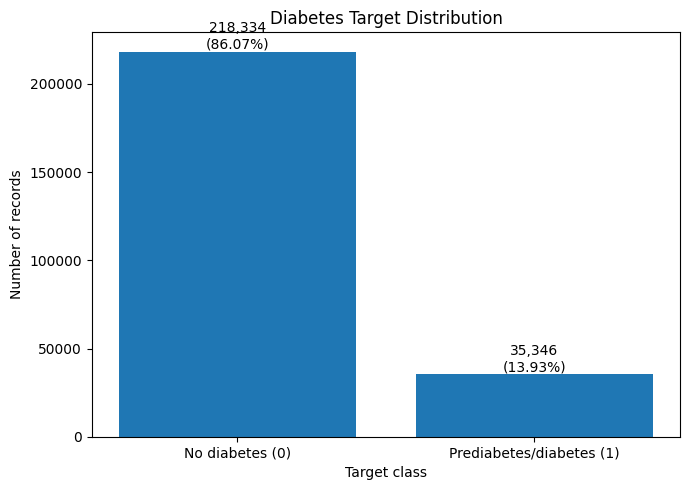

In [6]:
# ============================================================
# Step 3B: Target Distribution
# Purpose: Visualize class imbalance before model development.
# ============================================================

import matplotlib.pyplot as plt

target_counts = target.value_counts().sort_index()
target_percentages = target_counts / len(target) * 100

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No diabetes (0)", "Prediabetes/diabetes (1)"],
    target_counts.values,
)

ax.set_title("Diabetes Target Distribution")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of records")
ax.ticklabel_format(axis="y", style="plain")

for bar, count, percentage in zip(
    bars, target_counts.values, target_percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## Investigate duplicate-feature target conflicts

In [7]:
# ============================================================
# Step 3C: Duplicate Feature Conflict Analysis
# Purpose: Check whether identical feature vectors have
#          different target labels.
# ============================================================

audit_df = X.copy()
audit_df["_target"] = target.to_numpy()

duplicate_feature_mask = X.duplicated(keep=False)

duplicate_records = audit_df.loc[duplicate_feature_mask]

print("Records belonging to repeated feature vectors:",
      len(duplicate_records))

if duplicate_records.empty:
    print("No repeated feature vectors found.")
else:
    target_variants = (
        duplicate_records
        .groupby(list(X.columns), sort=False)["_target"]
        .nunique()
    )

    conflicting_groups = target_variants[target_variants > 1]

    print("Repeated feature groups:", len(target_variants))
    print("Groups with conflicting target labels:",
          len(conflicting_groups))

Records belonging to repeated feature vectors: 38000
Repeated feature groups: 12228
Groups with conflicting target labels: 1566


## Inspect selected feature distributions

,count,mean,std,min,25%,50%,75%,max
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Age,253680.0,8.032119,3.054220,1.0,6.0,8.0,10.0,13.0
GenHlth,253680.0,2.511392,1.068477,1.0,2.0,2.0,3.0,5.0
MentHlth,253680.0,3.184772,7.412847,0.0,0.0,0.0,2.0,30.0
PhysHlth,253680.0,4.242081,8.717951,0.0,0.0,0.0,3.0,30.0


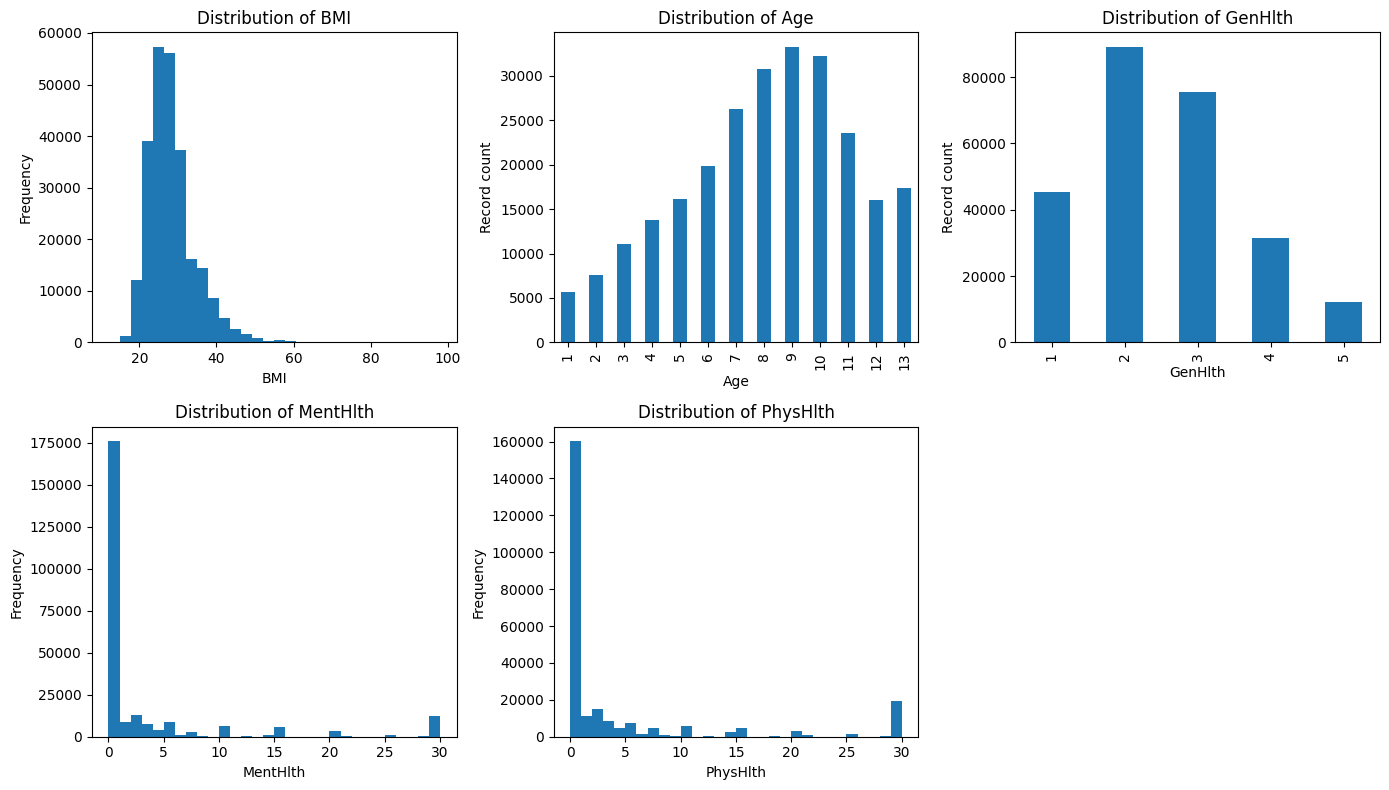

In [8]:
# ============================================================
# Step 3D: Selected Feature Distributions
# Purpose: Inspect representative binary, ordinal, and
#          numerical features.
# ============================================================

selected_features = ["BMI", "Age", "GenHlth", "MentHlth", "PhysHlth"]

display(X[selected_features].describe().T)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, column in zip(axes, selected_features):
    if X[column].nunique() <= 15:
        X[column].value_counts().sort_index().plot(
            kind="bar", ax=ax
        )
        ax.set_ylabel("Record count")
    else:
        ax.hist(X[column], bins=30)
        ax.set_ylabel("Frequency")

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

## Train, Validation, and Test Split

The dataset will be partitioned into training, validation, and test subsets using stratified group splitting.

Groups are defined by identical feature vectors. This prevents exact duplicate feature vectors from appearing across multiple subsets and reduces the risk of overly optimistic evaluation caused by duplicate-feature leakage.

Stratification aims to preserve the target-class distribution across subsets. Because grouping constrains the split, the final proportions may differ slightly from the nominal 70/15/15 allocation.

The training set will be used to fit preprocessing transformations and model parameters. The validation set will guide model selection and hyperparameter tuning. The test set will be reserved for final evaluation.

No preprocessing transformation will be fitted on validation or test data.


In [9]:
# ============================================================
# Step 4A: Leakage-Aware Data Splitting
# Purpose:
#   1. Group identical feature vectors.
#   2. Preserve class proportions as far as possible.
#   3. Keep groups isolated across train/validation/test.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

# Use a one-dimensional target array for scikit-learn.
y_array = y.iloc[:, 0].to_numpy(dtype=np.int64)

# Identical feature vectors receive the same group identifier.
groups = pd.util.hash_pandas_object(
    X, index=False
).to_numpy(dtype=np.uint64)

# First split: approximately 1/7 of groups for testing.
test_splitter = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=SEED,
)

trainval_idx, test_idx = next(
    test_splitter.split(X, y_array, groups=groups)
)

# Split the remaining records into training and validation.
X_trainval = X.iloc[trainval_idx]
y_trainval = y_array[trainval_idx]
groups_trainval = groups[trainval_idx]

val_splitter = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=SEED,
)

train_idx_rel, val_idx_rel = next(
    val_splitter.split(
        X_trainval,
        y_trainval,
        groups=groups_trainval,
    )
)

# Build the final datasets.
X_train = X_trainval.iloc[train_idx_rel].copy()
X_val = X_trainval.iloc[val_idx_rel].copy()
X_test = X.iloc[test_idx].copy()

y_train = y_trainval[train_idx_rel]
y_val = y_trainval[val_idx_rel]
y_test = y_array[test_idx]

groups_train = groups_trainval[train_idx_rel]
groups_val = groups_trainval[val_idx_rel]
groups_test = groups[test_idx]

print("Split sizes:")
for name, subset in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test),
]:
    print(
        f"{name:10s}: {len(subset):,} "
        f"({len(subset) / len(X) * 100:.2f}%)"
    )

print("\nPositive-class percentages:")
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test),
]:
    print(f"{name:10s}: {labels.mean() * 100:.2f}%")

# Verify that no identical-feature group crosses split boundaries.
train_groups = set(groups_train)
val_groups = set(groups_val)
test_groups = set(groups_test)

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("\nValidation passed: no feature groups overlap across splits.")

Split sizes:
Train     : 181,036 (71.36%)
Validation: 36,323 (14.32%)
Test      : 36,321 (14.32%)

Positive-class percentages:
Train     : 14.01%
Validation: 13.68%
Test      : 13.82%

Validation passed: no feature groups overlap across splits.


##  Feature Preprocessing

A column-aware preprocessing pipeline will be used for the PyTorch MLP.

Continuous/count features and ordinal-coded features will be standardized using **StandardScaler**. Binary indicators will remain unchanged as 0/1 values.

The scaler will be fitted exclusively on the training subset. The same fitted transformation will then be applied to validation and test subsets to prevent preprocessing leakage.

The Random Forest baseline will use the unscaled feature values because tree-based models do not require feature standardization.

The fitted preprocessing transformer will be saved for reuse during Streamlit inference.


In [10]:
# ============================================================
# Step 5: Preprocessing Pipeline
# Purpose:
#   1. Standardize numerical and ordinal features.
#   2. Preserve binary indicators.
#   3. Fit transformations on training data only.
# ============================================================

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

continuous_features = [
    "BMI",
    "MentHlth",
    "PhysHlth",
]

ordinal_features = [
    "GenHlth",
    "Age",
    "Education",
    "Income",
]

binary_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex",
]

# Verify that the feature schema is complete and non-overlapping.
all_preprocessing_features = (
    continuous_features + ordinal_features + binary_features
)

assert len(all_preprocessing_features) == len(set(all_preprocessing_features))
assert set(all_preprocessing_features) == set(X_train.columns)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "scaled",
            StandardScaler(),
            continuous_features + ordinal_features,
        ),
        (
            "binary",
            "passthrough",
            binary_features,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Fit only on training data.
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to float32 for efficient PyTorch training.
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

# Validate shapes and numerical stability.
assert X_train_processed.shape[1] == len(X.columns)
assert X_val_processed.shape[1] == len(X.columns)
assert X_test_processed.shape[1] == len(X.columns)

assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()
assert np.isfinite(X_test_processed).all()

print("Train processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)
print("Test processed shape:", X_test_processed.shape)

print("\nAll transformed values are finite.")
print("Feature schema validated:", len(all_preprocessing_features), "features")
print("Preprocessor fitted on training data only.")

Train processed shape: (181036, 21)
Validation processed shape: (36323, 21)
Test processed shape: (36321, 21)

All transformed values are finite.
Feature schema validated: 21 features
Preprocessor fitted on training data only.


## Verify binary features remain unchanged

In [11]:
# ============================================================
# Step 5B: Binary Feature Validation
# Purpose: Ensure binary features remain encoded as 0 and 1.
# ============================================================

# ColumnTransformer outputs scaled columns first, then binary columns.
binary_start = len(continuous_features) + len(ordinal_features)
binary_end = binary_start + len(binary_features)

train_binary_processed = X_train_processed[
    :, binary_start:binary_end
]

unique_binary_values = np.unique(train_binary_processed)

print("Unique binary feature values:", unique_binary_values)

assert set(unique_binary_values.tolist()).issubset({0.0, 1.0})

print("Binary feature validation passed.")

Unique binary feature values: [0. 1.]
Binary feature validation passed.


## 9. PyTorch MLP Architecture

The baseline neural network uses 21 input features and two fully connected hidden layers containing 64 and 32 neurons.

ReLU activation functions introduce non-linearity. Dropout probabilities of 0.30 and 0.20 provide initial regularization. The output layer produces one logit for binary classification.

The model will use **BCEWithLogitsLoss**, which combines sigmoid-based binary classification loss with a numerically stable implementation.

Because the positive class is underrepresented, the initial experiment will use a positive-class weight calculated from the training labels only. Its effect on precision, recall, and F1-score will be assessed on validation data.

The network architecture and training configuration will be documented to support reproducibility.


## Convert data into PyTorch tensors

In [12]:
# ============================================================
# Step 6A: Convert Preprocessed Data to PyTorch Tensors
# Purpose: Prepare model inputs and binary target labels.
# ============================================================

from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.from_numpy(X_train_processed)
X_val_tensor = torch.from_numpy(X_val_processed)
X_test_tensor = torch.from_numpy(X_test_processed)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.float32
).reshape(-1, 1)

y_val_tensor = torch.tensor(
    y_val, dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test, dtype=torch.float32
).reshape(-1, 1)

print("Train tensors:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensors:", X_val_tensor.shape, y_val_tensor.shape)
print("Test tensors:", X_test_tensor.shape, y_test_tensor.shape)

print("Input dtype:", X_train_tensor.dtype)
print("Target dtype:", y_train_tensor.dtype)

assert X_train_tensor.dtype == torch.float32
assert y_train_tensor.dtype == torch.float32
assert set(torch.unique(y_train_tensor).tolist()).issubset({0.0, 1.0})

print("\nTensor validation passed.")

Train tensors: torch.Size([181036, 21]) torch.Size([181036, 1])
Validation tensors: torch.Size([36323, 21]) torch.Size([36323, 1])
Test tensors: torch.Size([36321, 21]) torch.Size([36321, 1])
Input dtype: torch.float32
Target dtype: torch.float32

Tensor validation passed.


## Calculate class weight

In [13]:
# ============================================================
# Step 6B: Calculate Training-Only Class Weight
# Purpose: Compensate for the minority positive class.
# ============================================================

positive_count = int((y_train == 1).sum())
negative_count = int((y_train == 0).sum())

positive_weight = negative_count / positive_count

print("Training negative samples:", negative_count)
print("Training positive samples:", positive_count)
print("Positive class weight:", round(positive_weight, 4))

Training negative samples: 155678
Training positive samples: 25358
Positive class weight: 6.1392


## Define the MLP model

In [14]:
# ============================================================
# Step 6C: Define the PyTorch MLP
# Purpose: Build and verify the binary classification network.
# ============================================================

import torch.nn as nn

class HealthMLP(nn.Module):
    def __init__(self, input_dim: int = 21):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(p=0.30),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p=0.20),

            nn.Linear(32, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


model = HealthMLP(
    input_dim=X_train_tensor.shape[1]
).to(DEVICE)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print("\nDevice:", DEVICE)
print("Trainable parameters:", total_parameters)

# Verify output dimensions without updating model weights.
model.eval()

with torch.no_grad():
    sample_logits = model(X_train_tensor[:8].to(DEVICE))

print("Sample output shape:", tuple(sample_logits.shape))

assert sample_logits.shape == (8, 1)

print("\nModel architecture validation passed.")

HealthMLP(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Device: cpu
Trainable parameters: 3521
Sample output shape: (8, 1)

Model architecture validation passed.


## 10. MLP Training

The MLP will be trained using mini-batch gradient descent with the Adam optimizer and **BCEWithLogitsLoss**.

The positive-class weight calculated from the training labels will be applied to the loss function to account for class imbalance.

Training and validation losses will be recorded for every epoch. Early stopping will terminate training when validation loss does not improve for a predefined number of consecutive epochs. The checkpoint with the lowest validation loss will be retained for subsequent evaluation.

The test set will not be used for optimization, early stopping, or checkpoint selection.

### Initial configuration

- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 1,024
- Maximum epochs: 30
- Early-stopping patience: 5 epochs
- Checkpoint criterion: Minimum validation loss


In [15]:
# ============================================================
# Step 7A: Training Configuration
# Purpose: Prepare mini-batches, optimizer, and loss function.
# ============================================================

import copy
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 1024
MAX_EPOCHS = 30
PATIENCE = 5
LEARNING_RATE = 1e-3

OUTPUT_DIR = Path("/content/health_prediction_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reproducible shuffle order for the training loader.
generator = torch.Generator().manual_seed(SEED)

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0,
)

# Full validation set fits comfortably in memory for this model.
X_val_device = X_val_tensor.to(DEVICE)
y_val_device = y_val_tensor.to(DEVICE)

positive_weight_tensor = torch.tensor(
    [positive_weight],
    dtype=torch.float32,
    device=DEVICE,
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=positive_weight_tensor
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

print("Training batches per epoch:", len(train_loader))
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early-stopping patience:", PATIENCE)
print("Learning rate:", LEARNING_RATE)
print("Checkpoint directory:", OUTPUT_DIR)

Training batches per epoch: 177
Batch size: 1024
Maximum epochs: 30
Early-stopping patience: 5
Learning rate: 0.001
Checkpoint directory: /content/health_prediction_outputs


## Train the MLP

In [16]:
# ============================================================
# Step 7B: MLP Training Loop
# Purpose:
#   - Train on mini-batches.
#   - Monitor weighted validation loss.
#   - Save the best model checkpoint.
#   - Stop early if validation loss stops improving.
# ============================================================

history = {
    "train_loss": [],
    "val_loss": [],
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

checkpoint_path = OUTPUT_DIR / "health_mlp_best.pt"

for epoch in range(1, MAX_EPOCHS + 1):
    # -------------------------
    # Training phase
    # -------------------------
    model.train()

    total_train_loss = 0.0
    total_train_samples = 0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(DEVICE)
        batch_y = batch_y.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch_X)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        batch_size = batch_X.size(0)
        total_train_loss += loss.item() * batch_size
        total_train_samples += batch_size

    train_loss = total_train_loss / total_train_samples

    # -------------------------
    # Validation phase
    # -------------------------
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_device)
        val_loss = criterion(
            val_logits, y_val_device
        ).item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # -------------------------
    # Checkpoint selection
    # -------------------------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            checkpoint_path,
        )
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Best Epoch: {best_epoch}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}. "
            f"Best epoch: {best_epoch}"
        )
        break

print("\nTraining completed.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best epoch: {best_epoch}")
print(f"Checkpoint exists: {checkpoint_path.exists()}")

Epoch 01/30 | Train Loss: 0.9516 | Validation Loss: 0.8704 | Best Epoch: 1
Epoch 02/30 | Train Loss: 0.8941 | Validation Loss: 0.8639 | Best Epoch: 2
Epoch 03/30 | Train Loss: 0.8883 | Validation Loss: 0.8621 | Best Epoch: 3
Epoch 04/30 | Train Loss: 0.8847 | Validation Loss: 0.8612 | Best Epoch: 4
Epoch 05/30 | Train Loss: 0.8833 | Validation Loss: 0.8600 | Best Epoch: 5
Epoch 06/30 | Train Loss: 0.8804 | Validation Loss: 0.8590 | Best Epoch: 6
Epoch 07/30 | Train Loss: 0.8797 | Validation Loss: 0.8578 | Best Epoch: 7
Epoch 08/30 | Train Loss: 0.8795 | Validation Loss: 0.8578 | Best Epoch: 8
Epoch 09/30 | Train Loss: 0.8782 | Validation Loss: 0.8570 | Best Epoch: 9
Epoch 10/30 | Train Loss: 0.8765 | Validation Loss: 0.8566 | Best Epoch: 10
Epoch 11/30 | Train Loss: 0.8753 | Validation Loss: 0.8558 | Best Epoch: 11
Epoch 12/30 | Train Loss: 0.8761 | Validation Loss: 0.8569 | Best Epoch: 11
Epoch 13/30 | Train Loss: 0.8747 | Validation Loss: 0.8562 | Best Epoch: 11
Epoch 14/30 | Train L

## Restore best checkpoint and plot learning curves

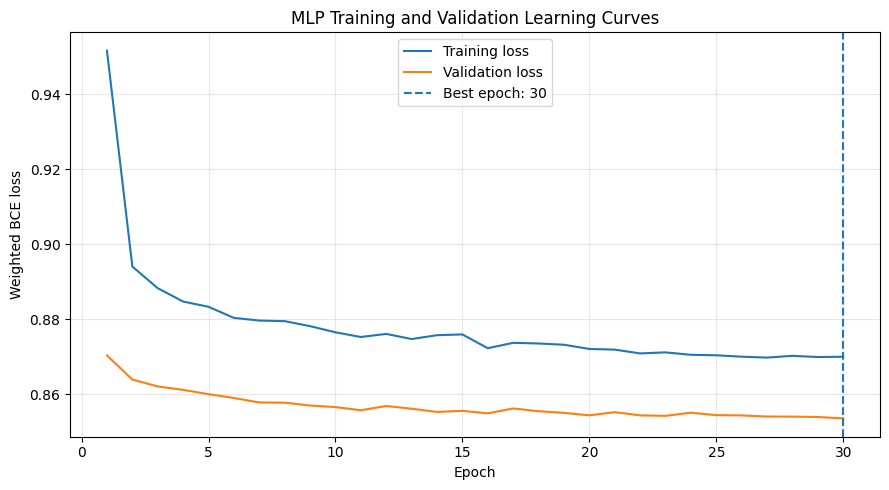

Restored checkpoint from epoch: 30
Checkpoint size (bytes): 17333


In [17]:
# ============================================================
# Step 7C: Restore Best Checkpoint and Plot Learning Curves
# Purpose: Analyze convergence and potential overfitting.
# ============================================================

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True,
    )
)

model.eval()

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Training loss",
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation loss",
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.title("MLP Training and Validation Learning Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Restored checkpoint from epoch:", best_epoch)
print("Checkpoint size (bytes):", checkpoint_path.stat().st_size)

## Learning Curve Analysis

Training aur validation loss ko epoch-wise plot kiya jayega. Is graph se pata chalega ke model learning improve kar raha hai ya training aur validation performance ke darmiyan gap barh raha hai.

The checkpoint with the lowest validation loss is restored before evaluation. The test set remains untouched during training and model selection.

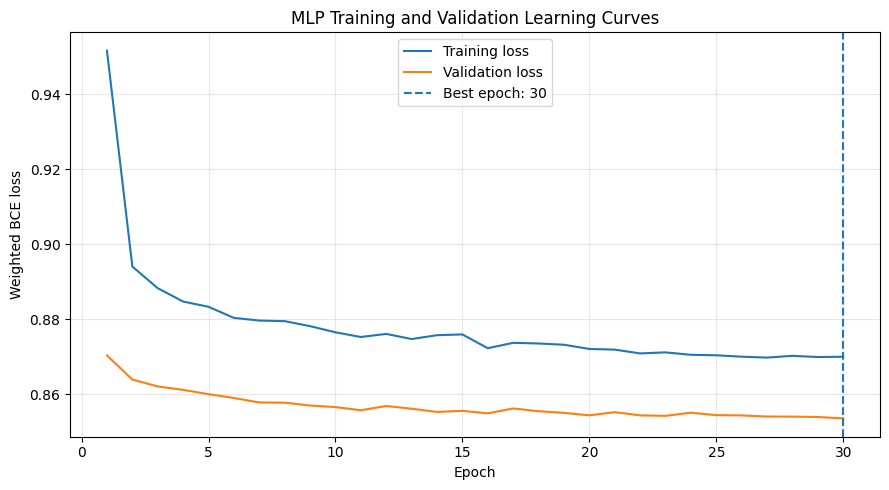

Restored best epoch: 30
Best validation loss: 0.8536
Checkpoint exists: True
Checkpoint size (bytes): 17333


In [18]:
# Restore the best model checkpoint
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )
)
model.eval()

# Plot learning curves
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, history["train_loss"], label="Training loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")
plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.title("MLP Training and Validation Learning Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Restored best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint exists:", checkpoint_path.exists())
print("Checkpoint size (bytes):", checkpoint_path.stat().st_size)

##  Validation Set Evaluation

The trained MLP is evaluated on the validation set using precision, recall, F1-score, ROC-AUC, average precision, and a confusion matrix.

The initial evaluation uses a probability threshold of 0.50. Because the dataset is imbalanced and the loss uses a positive-class weight, this threshold may not provide the best precision-recall trade-off. A threshold may therefore be selected using validation data only. Final performance will be measured on the untouched test set after model comparison.

MLP VALIDATION METRICS — THRESHOLD 0.50
Threshold: 0.5000
Accuracy: 0.7183
Precision: 0.3008
Recall: 0.7996
F1-score: 0.4371
ROC-AUC: 0.8299
Average Precision: 0.4260

Confusion Matrix:
[[22115  9238]
 [  996  3974]]

Classification Report:
                      precision    recall  f1-score   support

         No diabetes       0.96      0.71      0.81     31353
Prediabetes/diabetes       0.30      0.80      0.44      4970

            accuracy                           0.72     36323
           macro avg       0.63      0.75      0.62     36323
        weighted avg       0.87      0.72      0.76     36323



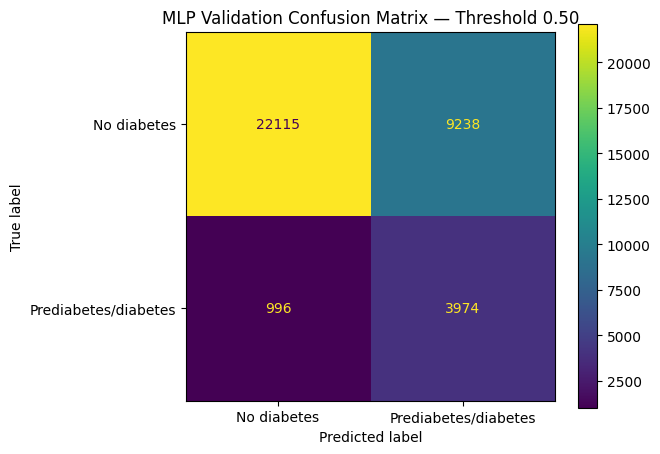

In [20]:

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# --------------------------------------------------
# 1. Restore the best checkpoint
# --------------------------------------------------
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True,
    )
)
model.eval()

# --------------------------------------------------
# 2. Generate validation probabilities
# --------------------------------------------------
with torch.no_grad():
    val_logits = model(X_val_tensor.to(DEVICE))
    val_probabilities = (
        torch.sigmoid(val_logits)
        .cpu()
        .numpy()
        .ravel()
    )

y_val_array = np.asarray(y_val).ravel().astype(int)

assert len(y_val_array) == len(val_probabilities)
assert np.isfinite(val_probabilities).all()

DEFAULT_THRESHOLD = 0.50
val_predictions_050 = (
    val_probabilities >= DEFAULT_THRESHOLD
).astype(int)

# --------------------------------------------------
# 3. Evaluate at the default threshold
# --------------------------------------------------
default_metrics = {
    "Threshold": DEFAULT_THRESHOLD,
    "Accuracy": accuracy_score(
        y_val_array, val_predictions_050
    ),
    "Precision": precision_score(
        y_val_array, val_predictions_050,
        zero_division=0,
    ),
    "Recall": recall_score(
        y_val_array, val_predictions_050,
        zero_division=0,
    ),
    "F1-score": f1_score(
        y_val_array, val_predictions_050,
        zero_division=0,
    ),
    "ROC-AUC": roc_auc_score(
        y_val_array, val_probabilities
    ),
    "Average Precision": average_precision_score(
        y_val_array, val_probabilities
    ),
}

print("MLP VALIDATION METRICS — THRESHOLD 0.50")
for metric, value in default_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
cm_050 = confusion_matrix(
    y_val_array,
    val_predictions_050,
    labels=[0, 1],
)
print(cm_050)

print("\nClassification Report:")
print(
    classification_report(
        y_val_array,
        val_predictions_050,
        labels=[0, 1],
        target_names=[
            "No diabetes",
            "Prediabetes/diabetes",
        ],
        zero_division=0,
    )
)

# --------------------------------------------------
# 4. Plot the confusion matrix
# --------------------------------------------------
ConfusionMatrixDisplay(
    confusion_matrix=cm_050,
    display_labels=[
        "No diabetes",
        "Prediabetes/diabetes",
    ],
).plot(values_format="d")

plt.title("MLP Validation Confusion Matrix — Threshold 0.50")
plt.tight_layout()
plt.show()


## Threshold tuning on validation data

BEST VALIDATION THRESHOLD
Threshold: 0.67
Accuracy:  0.8136
Precision: 0.3835
Recall:    0.5964
F1-score:  0.4668

Top 10 thresholds by F1-score:


,threshold,accuracy,precision,recall,f1
0,0.67,0.813617,0.383540,0.596378,0.466845
1,0.66,0.808881,0.377394,0.610664,0.466492
2,0.68,0.818049,0.389272,0.579678,0.465767
3,0.70,0.827988,0.404370,0.543662,0.463783
4,0.69,0.822619,0.395458,0.560563,0.463754
5,0.65,0.803155,0.369461,0.620724,0.463213
6,0.64,0.797842,0.363417,0.635211,0.462327
7,0.71,0.832696,0.412545,0.525352,0.462165
8,0.63,0.792638,0.357761,0.648290,0.461076
9,0.61,0.783471,0.349579,0.676861,0.461043


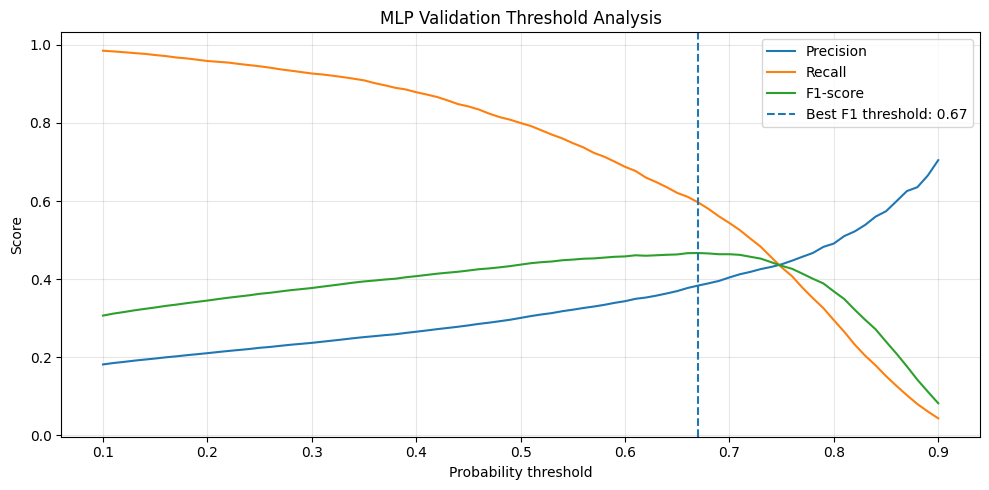


CONFUSION MATRIX — SELECTED THRESHOLD
[[26589  4764]
 [ 2006  2964]]

CLASSIFICATION REPORT — SELECTED THRESHOLD
                      precision    recall  f1-score   support

         No diabetes       0.93      0.85      0.89     31353
Prediabetes/diabetes       0.38      0.60      0.47      4970

            accuracy                           0.81     36323
           macro avg       0.66      0.72      0.68     36323
        weighted avg       0.86      0.81      0.83     36323



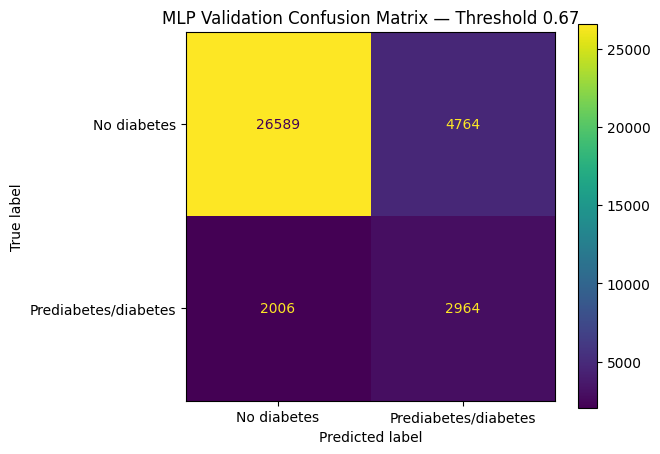

In [21]:

# --------------------------------------------------
# 1. Evaluate a range of thresholds
# --------------------------------------------------
threshold_rows = []

for threshold in np.round(
    np.arange(0.10, 0.901, 0.01), 2
):
    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_rows.append({
        "threshold": float(threshold),
        "accuracy": accuracy_score(
            y_val_array, predictions
        ),
        "precision": precision_score(
            y_val_array, predictions,
            zero_division=0,
        ),
        "recall": recall_score(
            y_val_array, predictions,
            zero_division=0,
        ),
        "f1": f1_score(
            y_val_array, predictions,
            zero_division=0,
        ),
    })

threshold_results = pd.DataFrame(threshold_rows)

# --------------------------------------------------
# 2. Select the threshold with the highest F1-score
# --------------------------------------------------
best_row = threshold_results.loc[
    threshold_results["f1"].idxmax()
]

MLP_THRESHOLD = float(best_row["threshold"])

print("BEST VALIDATION THRESHOLD")
print(f"Threshold: {MLP_THRESHOLD:.2f}")
print(f"Accuracy:  {best_row['accuracy']:.4f}")
print(f"Precision: {best_row['precision']:.4f}")
print(f"Recall:    {best_row['recall']:.4f}")
print(f"F1-score:  {best_row['f1']:.4f}")

print("\nTop 10 thresholds by F1-score:")
display(
    threshold_results
    .sort_values(
        ["f1", "precision"],
        ascending=[False, False],
    )
    .head(10)
    .reset_index(drop=True)
)

# --------------------------------------------------
# 3. Plot precision, recall, and F1 across thresholds
# --------------------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    label="Precision",
)
plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    label="Recall",
)
plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    label="F1-score",
)

plt.axvline(
    MLP_THRESHOLD,
    linestyle="--",
    label=f"Best F1 threshold: {MLP_THRESHOLD:.2f}",
)

plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("MLP Validation Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. Detailed results at the selected threshold
# --------------------------------------------------
val_predictions_best = (
    val_probabilities >= MLP_THRESHOLD
).astype(int)

print("\nCONFUSION MATRIX — SELECTED THRESHOLD")
cm_best = confusion_matrix(
    y_val_array,
    val_predictions_best,
    labels=[0, 1],
)
print(cm_best)

print("\nCLASSIFICATION REPORT — SELECTED THRESHOLD")
print(
    classification_report(
        y_val_array,
        val_predictions_best,
        labels=[0, 1],
        target_names=[
            "No diabetes",
            "Prediabetes/diabetes",
        ],
        zero_division=0,
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=[
        "No diabetes",
        "Prediabetes/diabetes",
    ],
).plot(values_format="d")

plt.title(
    f"MLP Validation Confusion Matrix — "
    f"Threshold {MLP_THRESHOLD:.2f}"
)
plt.tight_layout()
plt.show()


## Notebook results summary

In [22]:

mlp_validation_summary = pd.DataFrame([
    {
        "Model": "MLP",
        "Threshold": DEFAULT_THRESHOLD,
        "Accuracy": default_metrics["Accuracy"],
        "Precision": default_metrics["Precision"],
        "Recall": default_metrics["Recall"],
        "F1-score": default_metrics["F1-score"],
        "ROC-AUC": default_metrics["ROC-AUC"],
        "Average Precision": default_metrics["Average Precision"],
    },
    {
        "Model": "MLP",
        "Threshold": MLP_THRESHOLD,
        "Accuracy": accuracy_score(
            y_val_array, val_predictions_best
        ),
        "Precision": precision_score(
            y_val_array, val_predictions_best,
            zero_division=0,
        ),
        "Recall": recall_score(
            y_val_array, val_predictions_best,
            zero_division=0,
        ),
        "F1-score": f1_score(
            y_val_array, val_predictions_best,
            zero_division=0,
        ),
        "ROC-AUC": roc_auc_score(
            y_val_array, val_probabilities
        ),
        "Average Precision": average_precision_score(
            y_val_array, val_probabilities
        ),
    },
])

display(
    mlp_validation_summary.round(4)
)


,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,MLP,0.50,0.7183,0.3008,0.7996,0.4371,0.8299,0.426
1,MLP,0.67,0.8136,0.3835,0.5964,0.4668,0.8299,0.426


##  Random Forest Baseline

A Random Forest classifier is trained as a baseline for the MLP. It uses the original, unscaled feature values because tree-based models do not generally require standardization.

The same group-aware training and validation split is retained for a fair comparison. Class weighting is enabled to account for the imbalanced target. Model performance is evaluated on validation data using precision, recall, F1-score, ROC-AUC, and average precision. The test set remains reserved for final evaluation.

## Train Random Forest

In [23]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier

# Reproducible baseline configuration
RF_N_ESTIMATORS = 200
RF_MIN_SAMPLES_LEAF = 2

# Ensure labels are one-dimensional integers
y_train_rf = np.asarray(y_train).ravel().astype(int)
y_val_rf = np.asarray(y_val).ravel().astype(int)

# Use original, unscaled features
rf_model = RandomForestClassifier(
    n_estimators=RF_N_ESTIMATORS,
    min_samples_leaf=RF_MIN_SAMPLES_LEAF,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1,
)

print("Training Random Forest...")
print("Training samples:", len(X_train))
print("Number of features:", X_train.shape[1])
print("Trees:", RF_N_ESTIMATORS)
print("Minimum samples per leaf:", RF_MIN_SAMPLES_LEAF)

start_time = time.time()

rf_model.fit(X_train, y_train_rf)

rf_training_seconds = time.time() - start_time

print("\nRandom Forest training completed.")
print(f"Training time: {rf_training_seconds:.2f} seconds")
print("Number of fitted trees:", len(rf_model.estimators_))


Training Random Forest...
Training samples: 181036
Number of features: 21
Trees: 200
Minimum samples per leaf: 2

Random Forest training completed.
Training time: 53.13 seconds
Number of fitted trees: 200


## Validation evaluation and threshold selection

RANDOM FOREST — THRESHOLD 0.50
Model: Random Forest
Threshold: 0.5000
Accuracy: 0.8434
Precision: 0.4255
Recall: 0.4131
F1-score: 0.4192
ROC-AUC: 0.8157
Average Precision: 0.3957

Confusion matrix:
[[28581  2772]
 [ 2917  2053]]

Classification report:
                      precision    recall  f1-score   support

         No diabetes       0.91      0.91      0.91     31353
Prediabetes/diabetes       0.43      0.41      0.42      4970

            accuracy                           0.84     36323
           macro avg       0.67      0.66      0.66     36323
        weighted avg       0.84      0.84      0.84     36323



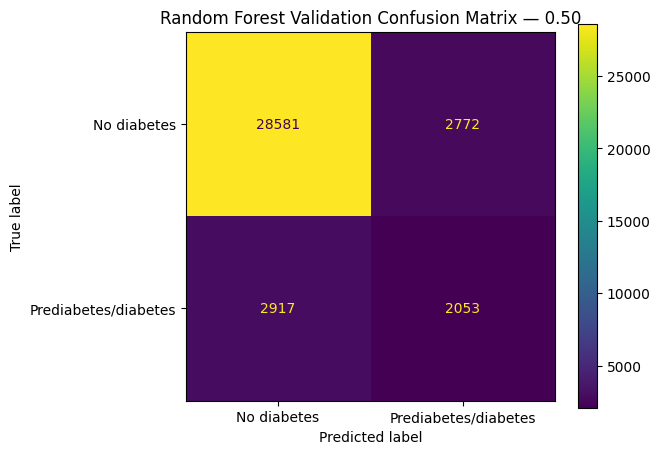


RANDOM FOREST — BEST VALIDATION F1 THRESHOLD
Threshold: 0.40
Precision: 0.3671
Recall:    0.5769
F1-score:  0.4487

Top 10 thresholds by F1-score:


,threshold,precision,recall,f1
0,0.40,0.367093,0.576861,0.448670
1,0.37,0.348908,0.623541,0.447444
2,0.36,0.343892,0.640040,0.447398
3,0.39,0.359706,0.590946,0.447202
4,0.41,0.371684,0.560966,0.447117
5,0.35,0.338809,0.655734,0.446775
6,0.38,0.353438,0.606036,0.446487
7,0.42,0.375401,0.541650,0.443456
8,0.34,0.331701,0.667807,0.443243
9,0.43,0.381188,0.526761,0.442304



Confusion matrix at selected threshold:
[[26410  4943]
 [ 2103  2867]]

Classification report at selected threshold:
                      precision    recall  f1-score   support

         No diabetes       0.93      0.84      0.88     31353
Prediabetes/diabetes       0.37      0.58      0.45      4970

            accuracy                           0.81     36323
           macro avg       0.65      0.71      0.67     36323
        weighted avg       0.85      0.81      0.82     36323



In [24]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# Obtain probability for the positive class (label 1)
rf_val_probabilities = rf_model.predict_proba(X_val)[:, 1]

assert len(rf_val_probabilities) == len(y_val_rf)
assert np.isfinite(rf_val_probabilities).all()

# Metrics at the default threshold
RF_DEFAULT_THRESHOLD = 0.50

rf_val_predictions_050 = (
    rf_val_probabilities >= RF_DEFAULT_THRESHOLD
).astype(int)

rf_default_metrics = {
    "Model": "Random Forest",
    "Threshold": RF_DEFAULT_THRESHOLD,
    "Accuracy": accuracy_score(
        y_val_rf, rf_val_predictions_050
    ),
    "Precision": precision_score(
        y_val_rf, rf_val_predictions_050,
        zero_division=0,
    ),
    "Recall": recall_score(
        y_val_rf, rf_val_predictions_050,
        zero_division=0,
    ),
    "F1-score": f1_score(
        y_val_rf, rf_val_predictions_050,
        zero_division=0,
    ),
    "ROC-AUC": roc_auc_score(
        y_val_rf, rf_val_probabilities
    ),
    "Average Precision": average_precision_score(
        y_val_rf, rf_val_probabilities
    ),
}

print("RANDOM FOREST — THRESHOLD 0.50")
for metric, value in rf_default_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nConfusion matrix:")
rf_cm_050 = confusion_matrix(
    y_val_rf,
    rf_val_predictions_050,
    labels=[0, 1],
)
print(rf_cm_050)

print("\nClassification report:")
print(
    classification_report(
        y_val_rf,
        rf_val_predictions_050,
        labels=[0, 1],
        target_names=[
            "No diabetes",
            "Prediabetes/diabetes",
        ],
        zero_division=0,
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=rf_cm_050,
    display_labels=[
        "No diabetes",
        "Prediabetes/diabetes",
    ],
).plot(values_format="d")

plt.title("Random Forest Validation Confusion Matrix — 0.50")
plt.tight_layout()
plt.show()

# Select the best F1 threshold using validation data only
rf_threshold_rows = []

for threshold in np.round(
    np.arange(0.10, 0.901, 0.01), 2
):
    predictions = (
        rf_val_probabilities >= threshold
    ).astype(int)

    rf_threshold_rows.append({
        "threshold": float(threshold),
        "precision": precision_score(
            y_val_rf, predictions,
            zero_division=0,
        ),
        "recall": recall_score(
            y_val_rf, predictions,
            zero_division=0,
        ),
        "f1": f1_score(
            y_val_rf, predictions,
            zero_division=0,
        ),
    })

rf_threshold_results = pd.DataFrame(rf_threshold_rows)

rf_best_row = rf_threshold_results.loc[
    rf_threshold_results["f1"].idxmax()
]

RF_THRESHOLD = float(rf_best_row["threshold"])

rf_val_predictions_best = (
    rf_val_probabilities >= RF_THRESHOLD
).astype(int)

print("\nRANDOM FOREST — BEST VALIDATION F1 THRESHOLD")
print(f"Threshold: {RF_THRESHOLD:.2f}")
print(f"Precision: {rf_best_row['precision']:.4f}")
print(f"Recall:    {rf_best_row['recall']:.4f}")
print(f"F1-score:  {rf_best_row['f1']:.4f}")

print("\nTop 10 thresholds by F1-score:")
display(
    rf_threshold_results
    .sort_values(
        ["f1", "precision"],
        ascending=[False, False],
    )
    .head(10)
    .reset_index(drop=True)
)

print("\nConfusion matrix at selected threshold:")
rf_cm_best = confusion_matrix(
    y_val_rf,
    rf_val_predictions_best,
    labels=[0, 1],
)
print(rf_cm_best)

print("\nClassification report at selected threshold:")
print(
    classification_report(
        y_val_rf,
        rf_val_predictions_best,
        labels=[0, 1],
        target_names=[
            "No diabetes",
            "Prediabetes/diabetes",
        ],
        zero_division=0,
    )
)


## MLP vs Random Forest comparison

In [25]:

# Reuse the existing MLP threshold results
mlp_default_row = mlp_validation_summary.iloc[0]
mlp_best_row = mlp_validation_summary.iloc[1]

rf_best_metrics = {
    "Model": "Random Forest",
    "Threshold": RF_THRESHOLD,
    "Accuracy": accuracy_score(
        y_val_rf, rf_val_predictions_best
    ),
    "Precision": precision_score(
        y_val_rf, rf_val_predictions_best,
        zero_division=0,
    ),
    "Recall": recall_score(
        y_val_rf, rf_val_predictions_best,
        zero_division=0,
    ),
    "F1-score": f1_score(
        y_val_rf, rf_val_predictions_best,
        zero_division=0,
    ),
    "ROC-AUC": roc_auc_score(
        y_val_rf, rf_val_probabilities
    ),
    "Average Precision": average_precision_score(
        y_val_rf, rf_val_probabilities
    ),
}

comparison_rows = [
    {
        "Model": "MLP",
        "Threshold": float(mlp_default_row["Threshold"]),
        "Accuracy": float(mlp_default_row["Accuracy"]),
        "Precision": float(mlp_default_row["Precision"]),
        "Recall": float(mlp_default_row["Recall"]),
        "F1-score": float(mlp_default_row["F1-score"]),
        "ROC-AUC": float(mlp_default_row["ROC-AUC"]),
        "Average Precision": float(
            mlp_default_row["Average Precision"]
        ),
    },
    {
        "Model": "MLP",
        "Threshold": float(mlp_best_row["Threshold"]),
        "Accuracy": float(mlp_best_row["Accuracy"]),
        "Precision": float(mlp_best_row["Precision"]),
        "Recall": float(mlp_best_row["Recall"]),
        "F1-score": float(mlp_best_row["F1-score"]),
        "ROC-AUC": float(mlp_best_row["ROC-AUC"]),
        "Average Precision": float(
            mlp_best_row["Average Precision"]
        ),
    },
    rf_default_metrics,
    rf_best_metrics,
]

validation_comparison = pd.DataFrame(comparison_rows)

display(
    validation_comparison.round(4)
)


,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,MLP,0.50,0.7183,0.3008,0.7996,0.4371,0.8299,0.4260
1,MLP,0.67,0.8136,0.3835,0.5964,0.4668,0.8299,0.4260
2,Random Forest,0.50,0.8434,0.4255,0.4131,0.4192,0.8157,0.3957
3,Random Forest,0.40,0.8060,0.3671,0.5769,0.4487,0.8157,0.3957


##  Final Test Set Evaluation

The MLP and Random Forest are evaluated on the held-out test set after model training, checkpoint selection, and threshold selection are complete.

The classification thresholds are fixed using validation data only. Test metrics include accuracy, precision, recall, F1-score, ROC-AUC, and average precision. Confusion matrices are used to examine false positives and false negatives.

The test set is not used to retrain models or tune thresholds. These results provide the final held-out comparison for this experiment.

Held-out test samples: 36321
Test positive rate: 0.1382

FINAL TEST-SET COMPARISON


,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,MLP,0.67,0.8147,0.3916,0.6162,0.4789,0.8370,0.4410
1,Random Forest,0.40,0.8088,0.3792,0.6030,0.4656,0.8253,0.4178



MLP — FINAL TEST RESULTS

Confusion matrix:
[[26499  4804]
 [ 1926  3092]]

Classification report:
                      precision    recall  f1-score   support

         No diabetes       0.93      0.85      0.89     31303
Prediabetes/diabetes       0.39      0.62      0.48      5018

            accuracy                           0.81     36321
           macro avg       0.66      0.73      0.68     36321
        weighted avg       0.86      0.81      0.83     36321



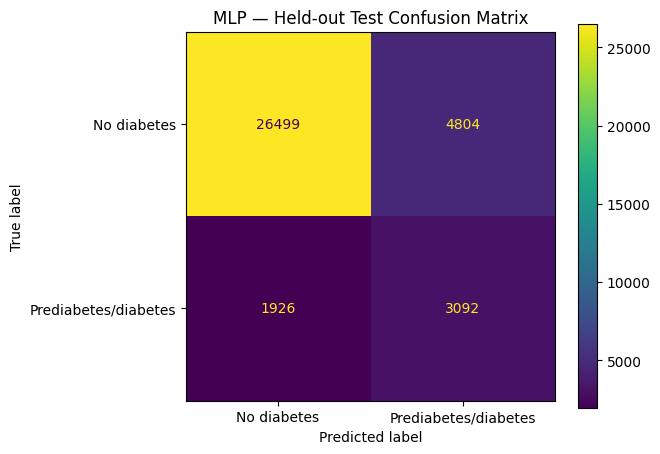


Random Forest — FINAL TEST RESULTS

Confusion matrix:
[[26349  4954]
 [ 1992  3026]]

Classification report:
                      precision    recall  f1-score   support

         No diabetes       0.93      0.84      0.88     31303
Prediabetes/diabetes       0.38      0.60      0.47      5018

            accuracy                           0.81     36321
           macro avg       0.65      0.72      0.67     36321
        weighted avg       0.85      0.81      0.83     36321



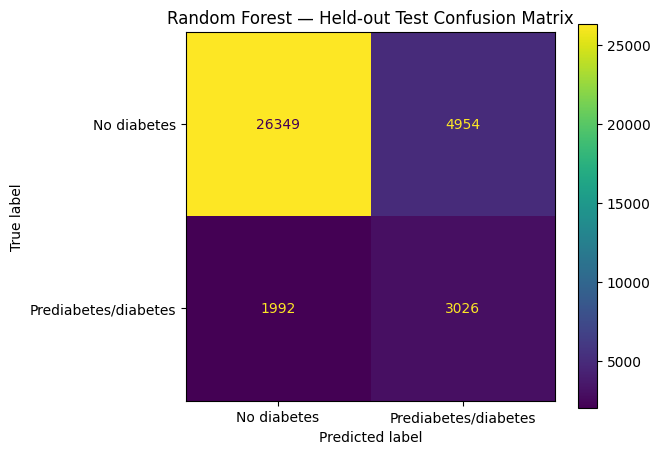

In [26]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Fix thresholds selected on validation data
# --------------------------------------------------
MLP_THRESHOLD = 0.67
RF_THRESHOLD = 0.40

# --------------------------------------------------
# 2. MLP predictions on the held-out test set
# --------------------------------------------------
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True,
    )
)
model.eval()

with torch.no_grad():
    test_logits = model(X_test_tensor.to(DEVICE))
    mlp_test_probabilities = (
        torch.sigmoid(test_logits)
        .cpu()
        .numpy()
        .ravel()
    )

y_test_array = np.asarray(y_test).ravel().astype(int)

mlp_test_predictions = (
    mlp_test_probabilities >= MLP_THRESHOLD
).astype(int)

# --------------------------------------------------
# 3. Random Forest predictions on the same test set
# --------------------------------------------------
rf_test_probabilities = rf_model.predict_proba(X_test)[:, 1]

rf_test_predictions = (
    rf_test_probabilities >= RF_THRESHOLD
).astype(int)

assert len(y_test_array) == len(mlp_test_probabilities)
assert len(y_test_array) == len(rf_test_probabilities)
assert np.isfinite(mlp_test_probabilities).all()
assert np.isfinite(rf_test_probabilities).all()

# --------------------------------------------------
# 4. Calculate final metrics
# --------------------------------------------------
def evaluate_binary_model(
    y_true,
    probabilities,
    threshold,
    model_name,
):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Average Precision": average_precision_score(
            y_true, probabilities
        ),
    }

test_comparison = pd.DataFrame([
    evaluate_binary_model(
        y_test_array,
        mlp_test_probabilities,
        MLP_THRESHOLD,
        "MLP",
    ),
    evaluate_binary_model(
        y_test_array,
        rf_test_probabilities,
        RF_THRESHOLD,
        "Random Forest",
    ),
])

print("Held-out test samples:", len(y_test_array))
print("Test positive rate:", round(y_test_array.mean(), 4))

print("\nFINAL TEST-SET COMPARISON")
display(test_comparison.round(4))

# --------------------------------------------------
# 5. Detailed classification reports
# --------------------------------------------------
for model_name, predictions in [
    ("MLP", mlp_test_predictions),
    ("Random Forest", rf_test_predictions),
]:
    print(f"\n{'=' * 55}")
    print(f"{model_name} — FINAL TEST RESULTS")
    print(f"{'=' * 55}")

    print("\nConfusion matrix:")
    cm = confusion_matrix(
        y_test_array,
        predictions,
        labels=[0, 1],
    )
    print(cm)

    print("\nClassification report:")
    print(
        classification_report(
            y_test_array,
            predictions,
            labels=[0, 1],
            target_names=[
                "No diabetes",
                "Prediabetes/diabetes",
            ],
            zero_division=0,
        )
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No diabetes",
            "Prediabetes/diabetes",
        ],
    ).plot(values_format="d")

    plt.title(
        f"{model_name} — Held-out Test Confusion Matrix"
    )
    plt.tight_layout()
    plt.show()


##  Model Artifact Export

The selected MLP checkpoint, fitted preprocessing pipeline, and trained Random Forest model are saved for reproducibility and deployment.

Metadata records the feature order, classification thresholds selected using validation data, model configuration, and held-out test metrics. The saved preprocessor must be reused at inference time; it must not be refitted on incoming application data.

The exported artifacts support subsequent Streamlit integration. The application is an educational demonstration and is not intended for clinical diagnosis.

## Save all artifacts and create a ZIP file

In [27]:

from pathlib import Path
import json
import zipfile
import joblib
import numpy as np
import pandas as pd
import sklearn
import torch

# --------------------------------------------------
# 1. Define output paths
# --------------------------------------------------
OUTPUT_DIR = Path("/content/health_prediction_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

mlp_path = OUTPUT_DIR / "health_mlp_best.pt"
preprocessor_path = OUTPUT_DIR / "preprocessor.joblib"
rf_path = OUTPUT_DIR / "random_forest.joblib"
metadata_path = OUTPUT_DIR / "model_metadata.json"
metrics_path = OUTPUT_DIR / "test_metrics.csv"
requirements_path = OUTPUT_DIR / "requirements.txt"

# --------------------------------------------------
# 2. Save the best MLP weights
# --------------------------------------------------
# model should already contain the best validation checkpoint.
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True,
    )
)
model.eval()

torch.save(model.state_dict(), mlp_path)

# --------------------------------------------------
# 3. Save fitted preprocessing and Random Forest
# --------------------------------------------------
joblib.dump(preprocessor, preprocessor_path)
joblib.dump(rf_model, rf_path)

# --------------------------------------------------
# 4. Save final test metrics
# --------------------------------------------------
test_comparison.to_csv(metrics_path, index=False)

# --------------------------------------------------
# 5. Save metadata needed for inference
# --------------------------------------------------
metadata = {
    "project_name": "Tabular Health Prediction",
    "dataset": "UCI CDC Diabetes Health Indicators",
    "uci_dataset_id": 891,
    "target_column": "Diabetes_binary",
    "target_mapping": {
        "0": "No diabetes",
        "1": "Prediabetes/diabetes",
    },
    "input_features": X.columns.tolist(),
    "number_of_features": int(X.shape[1]),
    "mlp": {
        "architecture": [21, 64, 32, 1],
        "dropout": [0.30, 0.20],
        "checkpoint_file": "health_mlp_best.pt",
        "threshold": float(MLP_THRESHOLD),
        "best_epoch": int(best_epoch),
        "best_validation_loss": float(best_val_loss),
        "positive_class_weight": float(positive_weight),
    },
    "random_forest": {
        "file": "random_forest.joblib",
        "threshold": float(RF_THRESHOLD),
        "n_estimators": int(RF_N_ESTIMATORS),
        "min_samples_leaf": int(RF_MIN_SAMPLES_LEAF),
    },
    "preprocessor_file": "preprocessor.joblib",
    "split_sizes": {
        "train": int(len(y_train)),
        "validation": int(len(y_val)),
        "test": int(len(y_test)),
    },
    "test_metrics": test_comparison.round(6).to_dict(
        orient="records"
    ),
    "environment": {
        "python_torch_version": torch.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "scikit_learn_version": sklearn.__version__,
    },
    "warning": (
        "Educational model only. Not clinically validated "
        "and not intended for medical diagnosis."
    ),
}

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(
        metadata,
        file,
        indent=2,
        default=lambda value: (
            value.item() if hasattr(value, "item") else str(value)
        ),
    )

# --------------------------------------------------
# 6. Write deployment dependencies
# --------------------------------------------------
requirements = """streamlit
torch
numpy
pandas
scikit-learn
joblib
matplotlib
"""

requirements_path.write_text(
    requirements,
    encoding="utf-8",
)

# --------------------------------------------------
# 7. Verify saved artifacts
# --------------------------------------------------
artifact_paths = [
    mlp_path,
    preprocessor_path,
    rf_path,
    metadata_path,
    metrics_path,
    requirements_path,
]

print("ARTIFACT VERIFICATION")
for path in artifact_paths:
    print(
        f"{path.name}: exists={path.exists()}, "
        f"size={path.stat().st_size if path.exists() else 0} bytes"
    )

assert all(path.exists() for path in artifact_paths)

# --------------------------------------------------
# 8. Create a ZIP archive
# --------------------------------------------------
zip_path = Path("/content/health_prediction_artifacts.zip")

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for path in artifact_paths:
        archive.write(path, arcname=path.name)

print("\nZIP archive created:", zip_path)
print("ZIP size (bytes):", zip_path.stat().st_size)


ARTIFACT VERIFICATION
health_mlp_best.pt: exists=True, size=17333 bytes
preprocessor.joblib: exists=True, size=3059 bytes
random_forest.joblib: exists=True, size=590922457 bytes
model_metadata.json: exists=True, size=1992 bytes
test_metrics.csv: exists=True, size=335 bytes
requirements.txt: exists=True, size=60 bytes

ZIP archive created: /content/health_prediction_artifacts.zip
ZIP size (bytes): 131244839


In [28]:

from google.colab import files

files.download("/content/health_prediction_artifacts.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>